# 02 — Feature extraction and exploratory analysis

This notebook summarizes the figure-of-merit (FoM) extraction and the
device-grouped train/validation/test split. It reads the processed tables; it
does not regenerate the raw data.

FoM definitions:

| FoM | Definition |
|---|---|
| `Ioff` | `Id` at `Vgs = 0 V` |
| `Ion` | `Id` at `Vgs = 1.0 V` |
| `Vth` | constant-current threshold at `1e-8 A/µm` (fallback `1e-9`, then max-gm) |
| `gm_max` | maximum transconductance in the valid region |
| `SS_min` | minimum subthreshold swing in the valid region |

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT = Path.cwd()
if not (PROJECT / "data").exists():
    PROJECT = PROJECT.parent
PROC = PROJECT / "data" / "processed"
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.25})

fom = pd.read_csv(PROC / "dg_tfet_fom.csv")
fom_all = pd.read_csv(PROC / "fom_all_splits.csv")
quality = json.loads((PROC / "data_quality.json").read_text())
prep = json.loads((PROC / "preprocessing_info.json").read_text())

summary = pd.DataFrame(
    {
        "value": [
            quality["n_devices_total"],
            quality["n_devices_valid"],
            quality["n_curves_total"],
            quality["n_curves_valid"],
            len(fom),
            prep["n_devices"]["train"],
            prep["n_devices"]["validation"],
            prep["n_devices"]["test"],
        ]
    },
    index=[
        "devices generated",
        "devices with ≥1 valid curve",
        "curves generated (device × Vds)",
        "valid curves",
        "valid FoM rows",
        "train devices",
        "validation devices",
        "test devices",
    ],
)
display(summary)
print("valid curves by Vds:")
display(pd.DataFrame(quality["valid_by_vds"]).T)
print("exclusion reasons:")
display(pd.Series(quality["exclusion_reasons"], name="count").sort_values(ascending=False))

,value
devices generated,512
devices with ≥1 valid curve,491
curves generated (device × Vds),1536
valid curves,1268
valid FoM rows,1268
train devices,344
validation devices,74
test devices,73


valid curves by Vds:


,total,valid
0.1,512,318
0.3,512,461
0.5,512,489


exclusion reasons:


ion_out_of_range                                                        123
ion_out_of_range;ss_undefined;vth_undefined                              65
ion_out_of_range;vth_undefined                                           48
ion_out_of_range;ion_ioff_ratio_below_100;ss_undefined;vth_undefined     25
non_finite_or_nonpositive_current                                         6
ion_out_of_range;ion_ioff_ratio_below_100;ss_undefined                    1
Name: count, dtype: int64

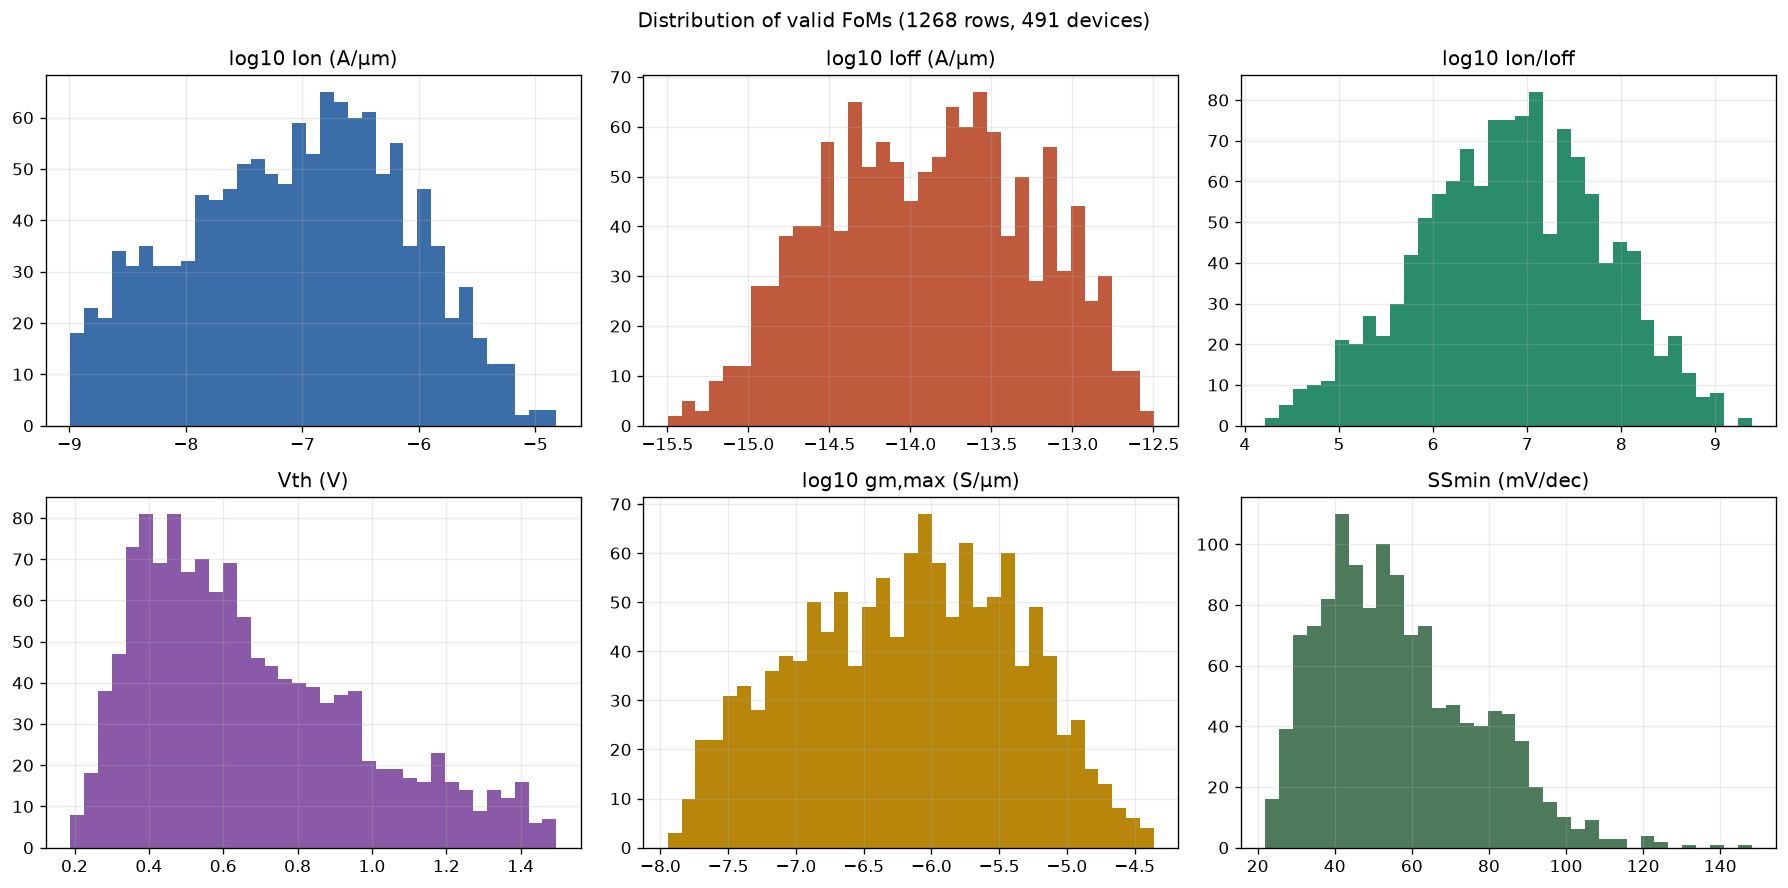

,count,mean,std,min,25%,50%,75%,max
Ion_A_per_um,1268.0,5.172057e-07,1.224917e-06,1.009705e-09,1.739419e-08,1.016083e-07,4.262296e-07,1.513716e-05
Ioff_A_per_um,1268.0,3.246425e-14,4.626975e-14,3.174022e-16,4.262321e-15,1.326470e-14,3.868390e-14,3.186000e-13
Ion_Ioff_ratio,1268.0,5.153980e+07,1.496347e+08,1.650654e+04,1.478184e+06,7.132589e+06,3.493290e+07,2.424706e+09
Vth_V,1268.0,6.750863e-01,2.973678e-01,1.878506e-01,4.383833e-01,6.108087e-01,8.628463e-01,1.495873e+00
gm_max_S_per_um,1268.0,2.560529e-06,4.751036e-06,1.130440e-08,1.561853e-07,7.242254e-07,2.733052e-06,4.397558e-05
SS_min_mV_per_dec,1268.0,5.665431e+01,2.013369e+01,2.198345e+01,4.123138e+01,5.342395e+01,6.970393e+01,1.481565e+02


In [2]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
axes[0, 0].hist(np.log10(fom.Ion_A_per_um), bins=35, color="#3b6ea8")
axes[0, 0].set_title("log10 Ion (A/µm)")
axes[0, 1].hist(np.log10(fom.Ioff_A_per_um), bins=35, color="#c05a3c")
axes[0, 1].set_title("log10 Ioff (A/µm)")
axes[0, 2].hist(np.log10(fom.Ion_Ioff_ratio), bins=35, color="#2a8c6a")
axes[0, 2].set_title("log10 Ion/Ioff")
axes[1, 0].hist(fom.Vth_V, bins=35, color="#8a5aa8")
axes[1, 0].set_title("Vth (V)")
axes[1, 1].hist(np.log10(fom.gm_max_S_per_um), bins=35, color="#b8860b")
axes[1, 1].set_title("log10 gm,max (S/µm)")
axes[1, 2].hist(fom.SS_min_mV_per_dec, bins=35, color="#4c7a5a")
axes[1, 2].set_title("SSmin (mV/dec)")
fig.suptitle("Distribution of valid FoMs (1268 rows, 491 devices)")
fig.tight_layout()
plt.show()

display(fom[["Ion_A_per_um", "Ioff_A_per_um", "Ion_Ioff_ratio", "Vth_V", "gm_max_S_per_um", "SS_min_mV_per_dec"]].describe().T)

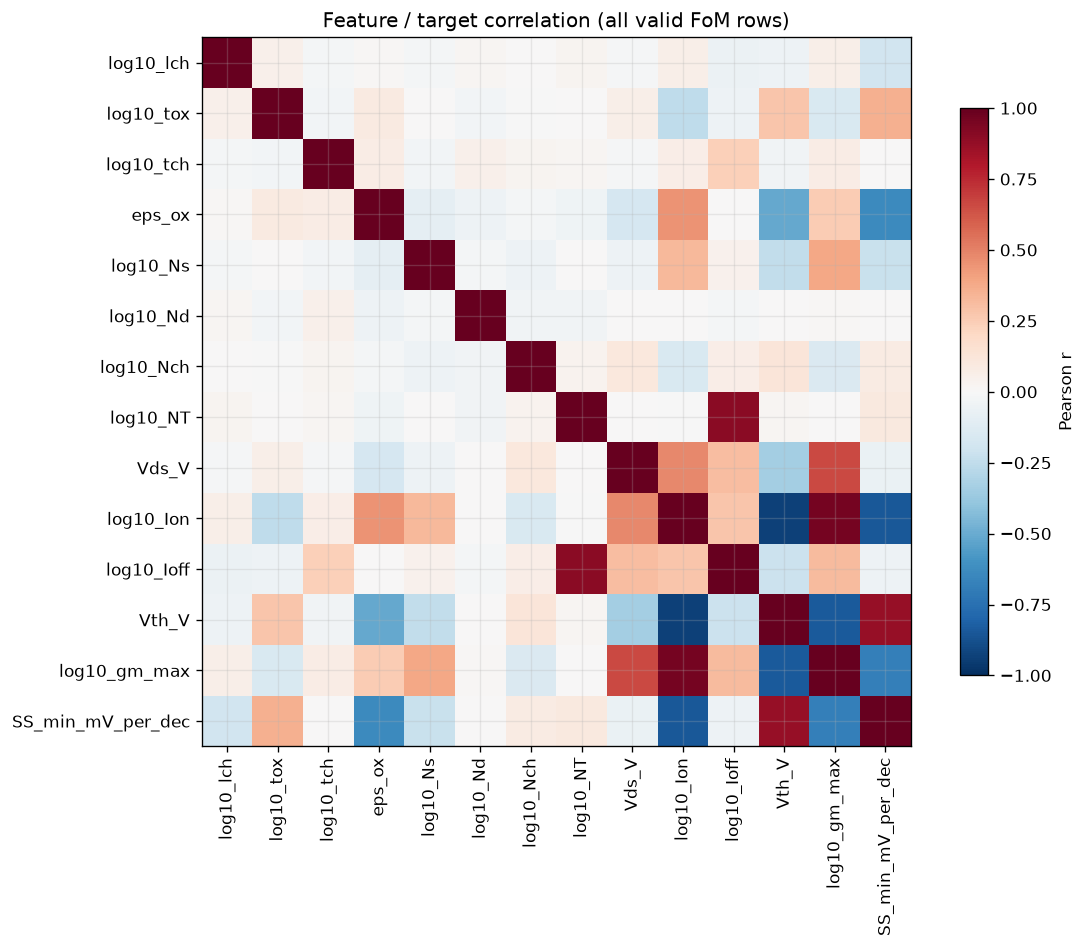

In [3]:
feat_cols = ["log10_lch", "log10_tox", "log10_tch", "eps_ox", "log10_Ns", "log10_Nd", "log10_Nch", "log10_NT", "Vds_V"]
target_cols = ["log10_Ion", "log10_Ioff", "Vth_V", "log10_gm_max", "SS_min_mV_per_dec"]
corr = fom_all[feat_cols + target_cols].corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Feature / target correlation (all valid FoM rows)")
fig.tight_layout()
plt.show()

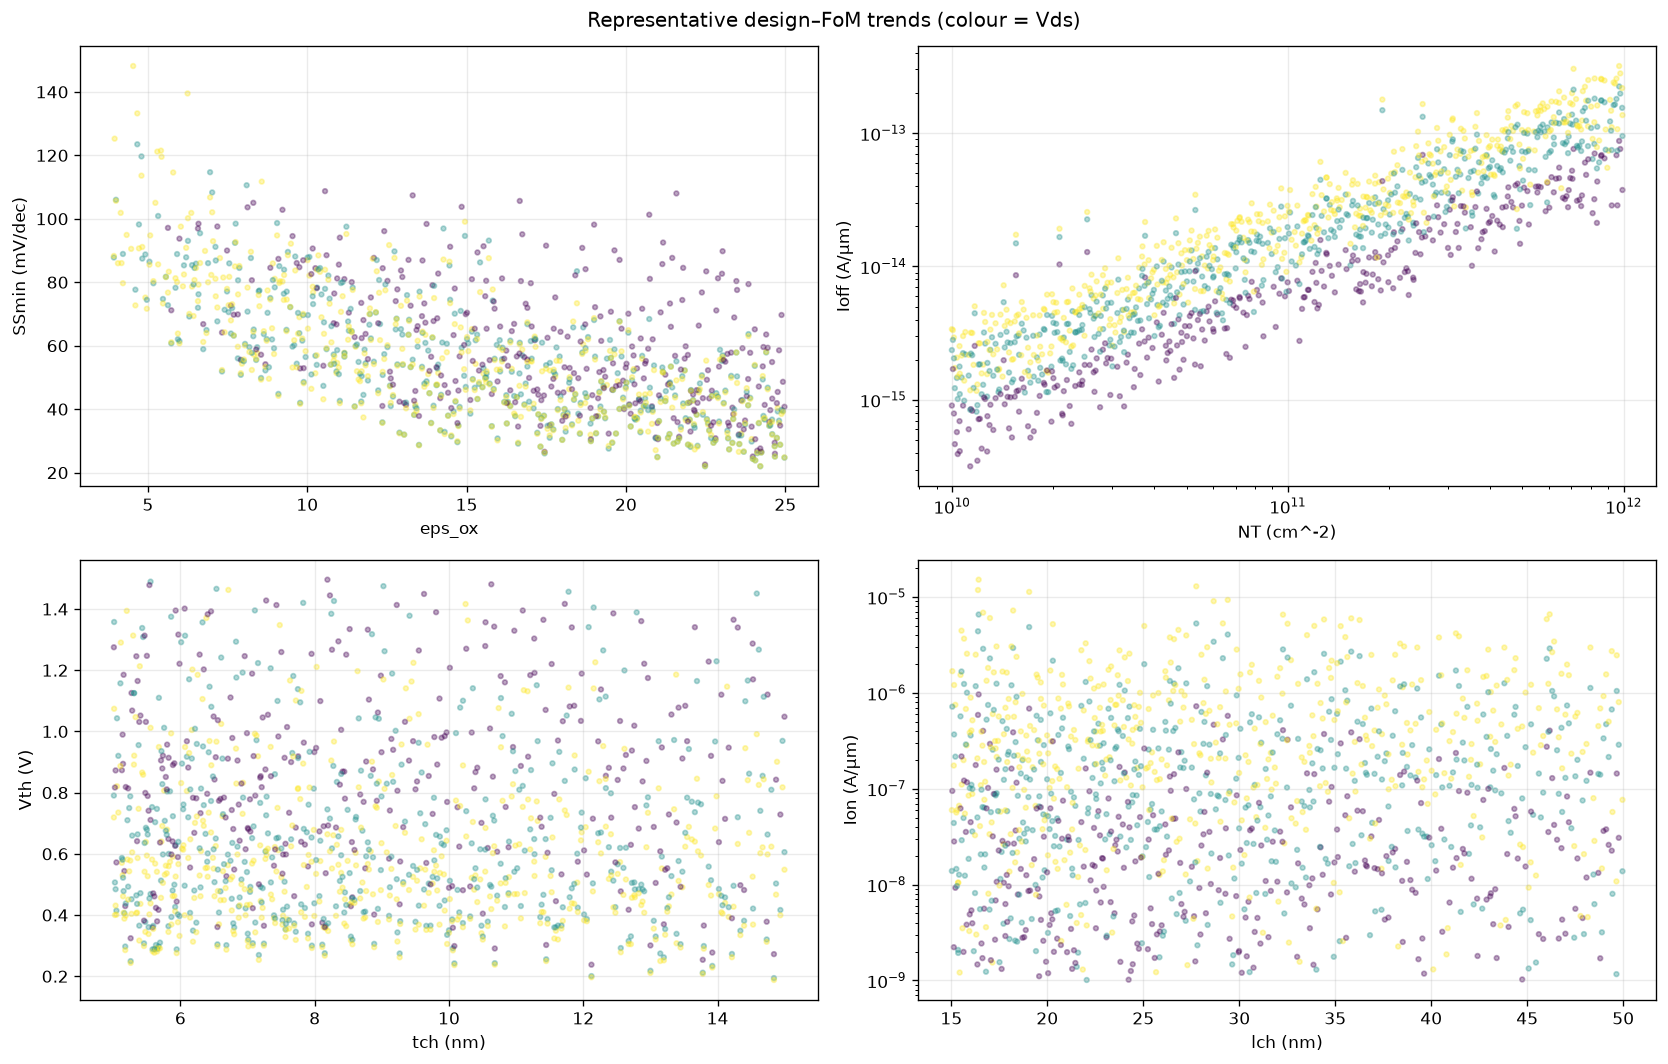

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes[0, 0].scatter(fom.eps_ox, fom.SS_min_mV_per_dec, s=8, alpha=0.35, c=fom.Vds_V, cmap="viridis")
axes[0, 0].set_xlabel("eps_ox")
axes[0, 0].set_ylabel("SSmin (mV/dec)")
axes[0, 1].scatter(fom.NT_cm2, fom.Ioff_A_per_um, s=8, alpha=0.35, c=fom.Vds_V, cmap="viridis")
axes[0, 1].set_xscale("log")
axes[0, 1].set_yscale("log")
axes[0, 1].set_xlabel("NT (cm^-2)")
axes[0, 1].set_ylabel("Ioff (A/µm)")
axes[1, 0].scatter(fom.tch_nm, fom.Vth_V, s=8, alpha=0.35, c=fom.Vds_V, cmap="viridis")
axes[1, 0].set_xlabel("tch (nm)")
axes[1, 0].set_ylabel("Vth (V)")
axes[1, 1].scatter(fom.lch_nm, fom.Ion_A_per_um, s=8, alpha=0.35, c=fom.Vds_V, cmap="viridis")
axes[1, 1].set_yscale("log")
axes[1, 1].set_xlabel("lch (nm)")
axes[1, 1].set_ylabel("Ion (A/µm)")
fig.suptitle("Representative design–FoM trends (colour = Vds)")
fig.tight_layout()
plt.show()

In [5]:
sets = {name: set(g.device_id.unique()) for name, g in fom_all.groupby("split")}
print("device overlap check")
for a in sets:
    for b in sets:
        if a < b:
            print(f"  {a} ∩ {b}: {len(sets[a] & sets[b])} devices")

rows = []
for target in ["log10_Ion", "log10_Ioff", "Vth_V", "log10_gm_max", "SS_min_mV_per_dec"]:
    for split in ["train", "validation", "test"]:
        g = fom_all[fom_all.split == split]
        rows.append({
            "target": target,
            "split": split,
            "n": len(g),
            "mean": g[target].mean(),
            "std": g[target].std(),
            "min": g[target].min(),
            "max": g[target].max(),
        })
display(pd.DataFrame(rows).pivot(index="target", columns="split", values=["mean", "std"]).round(4))

device overlap check
  test ∩ train: 0 devices
  test ∩ validation: 0 devices
  train ∩ validation: 0 devices


mean                          std                    
split                 test    train validation     test    train validation
target                                                                     
SS_min_mV_per_dec  58.7305  56.5251    55.2373  21.0155  19.6466    21.3930
Vth_V               0.7015   0.6725     0.6614   0.3031   0.2919     0.3163
log10_Ioff        -13.9065 -13.8820   -13.9333   0.6434   0.6336     0.6426
log10_Ion          -7.1324  -7.0605    -7.0009   0.9179   0.9182     0.9742
log10_gm_max       -6.2171  -6.1844    -6.1398   0.7892   0.7905     0.8119

### Split integrity

The split is by **device**, not by row. Every `(device_id, Vds)` curve belongs to
exactly one split, so validation and test devices never appear in training. This
is the critical leakage control for this dataset: rows from the same device are
strongly correlated.

The class imbalance in valid curves is visible by `Vds`: 318/512 devices are
valid at `0.1 V`, 461/512 at `0.3 V`, and 489/512 at `0.5 V`. The models therefore
see substantially more high-`Vds` data.